# Práctica 2. EDA y preparación de datasets

**Datasets:** Titanic (supervivencia, 891 filas) y Telco Customer Churn (abandono de clientes, 7,043 filas).

**Objetivo:** diagnosticar la calidad de los datos, justificar decisiones de preprocesamiento y medir su efecto sobre un clasificador (regresión logística con validación cruzada estratificada de 5 folds).

**Declaración de IA:** se usó Claude (Anthropic) como asistente para estructurar el código y apoyar la interpretación. El equipo ejecutó y revisó todo el código.

## 1. Carga de datos
Se cargan ambos archivos desde la carpeta `Data/`. Se verifican las dimensiones esperadas y la distribución de la clase objetivo.

In [ ]:
import pandas as pd
import os

base = "Data/" if os.path.exists("Data") else ""

titanic = pd.read_csv(base + "train.csv")
telco = pd.read_csv(base + "WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Titanic:", titanic.shape)
print("Telco:", telco.shape)
print(titanic["Survived"].value_counts())
print(telco["Churn"].value_counts())

Titanic: (891, 12)
Telco: (7043, 21)
Survived
0    549
1    342
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 2. Data profiling
Se definen funciones reutilizables que reportan, por dataset: tipo de dato, nulos, valores únicos, estadísticos (media, mediana, desviación, percentiles y asimetría), moda de las categóricas, filas duplicadas, columnas constantes e identificadores.

In [ ]:
import numpy as np

def perfil_general(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
        "%unicos": (df.nunique() / len(df) * 100).round(2),
    })

def perfil_numerico(df):
    num = df.select_dtypes(include="number")
    d = num.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    d["asimetria"] = num.skew()
    return d.round(2)

def perfil_categorico(df):
    cat = df.select_dtypes(exclude="number")
    return pd.DataFrame({
        "unicos": cat.nunique(),
        "moda": cat.mode().iloc[0],
        "%moda": [round(cat[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in cat],
    })

def chequeos(df):
    print("Filas duplicadas:", df.duplicated().sum())
    print("Columnas constantes:", [c for c in df if df[c].nunique(dropna=False) <= 1])
    print("Casi constantes (>95% un valor):",
          [c for c in df if df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95])
    print("Identificadores (100% únicos):", [c for c in df if df[c].nunique() == len(df)])

### Hallazgos del profiling de Titanic
- `Age` tiene 19.9 % de nulos, `Cabin` 77.1 % y `Embarked` solo 2 filas.
- `Fare` tiene asimetría de 4.79 (mediana 14.45, máximo 512.33).
- `PassengerId` y `Name` son identificadores únicos.
- No hay duplicados ni columnas constantes.

In [ ]:
display(perfil_general(titanic))
display(perfil_numerico(titanic))
display(perfil_categorico(titanic))
chequeos(titanic)

,tipo,nulos,%nulos,unicos,%unicos
PassengerId,int64,0,0.00,891,100.00
Survived,int64,0,0.00,2,0.22
Pclass,int64,0,0.00,3,0.34
Name,object,0,0.00,891,100.00
Sex,object,0,0.00,2,0.22
Age,float64,177,19.87,88,9.88
SibSp,int64,0,0.00,7,0.79
Parch,int64,0,0.00,7,0.79
Ticket,object,0,0.00,681,76.43
Fare,float64,0,0.00,248,27.83


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,asimetria
PassengerId,891.0,446.00,257.35,1.00,9.9,45.50,223.50,446.00,668.5,846.50,882.10,891.00,0.00
Survived,891.0,0.38,0.49,0.00,0.0,0.00,0.00,0.00,1.0,1.00,1.00,1.00,0.48
Pclass,891.0,2.31,0.84,1.00,1.0,1.00,2.00,3.00,3.0,3.00,3.00,3.00,-0.63
Age,714.0,29.70,14.53,0.42,1.0,4.00,20.12,28.00,38.0,56.00,65.87,80.00,0.39
SibSp,891.0,0.52,1.10,0.00,0.0,0.00,0.00,0.00,1.0,3.00,5.00,8.00,3.70
Parch,891.0,0.38,0.81,0.00,0.0,0.00,0.00,0.00,0.0,2.00,4.00,6.00,2.75
Fare,891.0,32.20,49.69,0.00,0.0,7.22,7.91,14.45,31.0,112.08,249.01,512.33,4.79


,unicos,moda,%moda
Name,891,"Abbing, Mr. Anthony",0.1
Sex,2,male,64.8
Ticket,681,1601,0.8
Cabin,147,B96 B98,2.0
Embarked,3,S,72.4


Filas duplicadas: 0
Columnas constantes: []
Casi constantes (>95% un valor): []
Identificadores (100% únicos): ['PassengerId', 'Name']


### Hallazgos del profiling de Telco
- `TotalCharges` viene como texto (`object`) porque contiene espacios en blanco.
- `customerID` es un identificador único y no se usa en el modelo.
- `SeniorCitizen` es numérica (0/1) pero en realidad es categórica.
- No hay duplicados ni columnas constantes.

In [ ]:
display(perfil_general(telco))
chequeos(telco)

,tipo,nulos,%nulos,unicos,%unicos
customerID,object,0,0.0,7043,100.00
gender,object,0,0.0,2,0.03
SeniorCitizen,int64,0,0.0,2,0.03
Partner,object,0,0.0,2,0.03
Dependents,object,0,0.0,2,0.03
tenure,int64,0,0.0,73,1.04
PhoneService,object,0,0.0,2,0.03
MultipleLines,object,0,0.0,3,0.04
InternetService,object,0,0.0,3,0.04
OnlineSecurity,object,0,0.0,3,0.04


Filas duplicadas: 0
Columnas constantes: []
Casi constantes (>95% un valor): []
Identificadores (100% únicos): ['customerID']


### Corrección de `TotalCharges`
Se verifica que las 11 filas vacías corresponden a clientes con `tenure = 0` (clientes nuevos sin facturación): la ausencia es **estructural, no aleatoria**. Después se convierte la columna a numérica (los vacíos pasan a `NaN`) y se perfilan las variables numéricas y categóricas de Telco.

In [ ]:
print(telco[telco["TotalCharges"].str.strip() == ""][["customerID", "tenure", "TotalCharges"]])

telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")

display(perfil_numerico(telco))
display(perfil_categorico(telco))

      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,asimetria
SeniorCitizen,7043.0,0.16,0.37,0.00,0.0,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.83
tenure,7043.0,32.37,24.56,0.00,1.0,1.00,9.00,29.00,55.00,72.00,72.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,19.2,19.65,35.50,70.35,89.85,107.40,114.73,118.75,-0.22
TotalCharges,7032.0,2283.30,2266.77,18.80,19.9,49.60,401.45,1397.48,3794.74,6923.59,8039.88,8684.80,0.96


,unicos,moda,%moda
customerID,7043,0002-ORFBO,0.0
gender,2,Male,50.5
Partner,2,No,51.7
Dependents,2,No,70.0
PhoneService,2,Yes,90.3
MultipleLines,3,No,48.1
InternetService,3,Fiber optic,44.0
OnlineSecurity,3,No,49.7
OnlineBackup,3,No,43.8
DeviceProtection,3,No,43.9


### Correlaciones, redundancias y valores sospechosos
- En Telco, `tenure` y `TotalCharges` tienen correlación 0.83: `TotalCharges` es casi `tenure x MonthlyCharges`.
- Las categorías "No internet service" (1,526) y "No phone service" (682) son redundantes con otras columnas.
- En Titanic hay 15 pasajeros con `Fare = 0`, un valor sospechoso que se documenta sin modificar.

In [ ]:
# Correlaciones elevadas
print(telco[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2))
print(titanic[["Pclass", "Age", "SibSp", "Parch", "Fare"]].corr().round(2))

# Categorías potencialmente redundantes en Telco
for c in ["MultipleLines", "OnlineSecurity", "InternetService"]:
    print(telco[c].value_counts(), "\n")

# Valores potencialmente inválidos en Titanic
print("Fare igual a 0:", (titanic["Fare"] == 0).sum())

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00
        Pclass   Age  SibSp  Parch  Fare
Pclass    1.00 -0.37   0.08   0.02 -0.55
Age      -0.37  1.00  -0.31  -0.19  0.10
SibSp     0.08 -0.31   1.00   0.41  0.16
Parch     0.02 -0.19   0.41   1.00  0.22
Fare     -0.55  0.10   0.16   0.22  1.00
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

Fare igual a 0: 15


## 3. Análisis exploratorio
**Titanic:** `Fare` tiene una cola muy larga a la derecha; la supervivencia es mucho mayor en mujeres y en 1.ª clase, y `Age` casi no separa las clases. La matriz de correlación no incluye `Sex` por ser categórica, aunque es la variable más influyente.

**Telco:** `tenure` es bimodal (muchos clientes nuevos y muchos muy antiguos). El abandono se concentra en contratos mensuales (aprox. 43 %, frente a 11 % a un año y 3 % a dos años), en fibra óptica y en clientes con poca antigüedad.

### EDA de Titanic
Cada gráfica responde una pregunta concreta:
- **Histogramas de `Age` y `Fare`:** ¿cómo se distribuyen y hay valores extremos?
- **Distribución de la clase:** ¿está desbalanceado el objetivo? (549 vs. 342)
- **Boxplots de `Age` y `Fare` por `Survived`:** ¿separan las clases estas variables?
- **Matriz de correlación:** ¿qué variables numéricas se relacionan con sobrevivir y entre sí?
- **`Sex`, `Pclass` y `Embarked` vs. `Survived`:** ¿qué grupos sobreviven más?

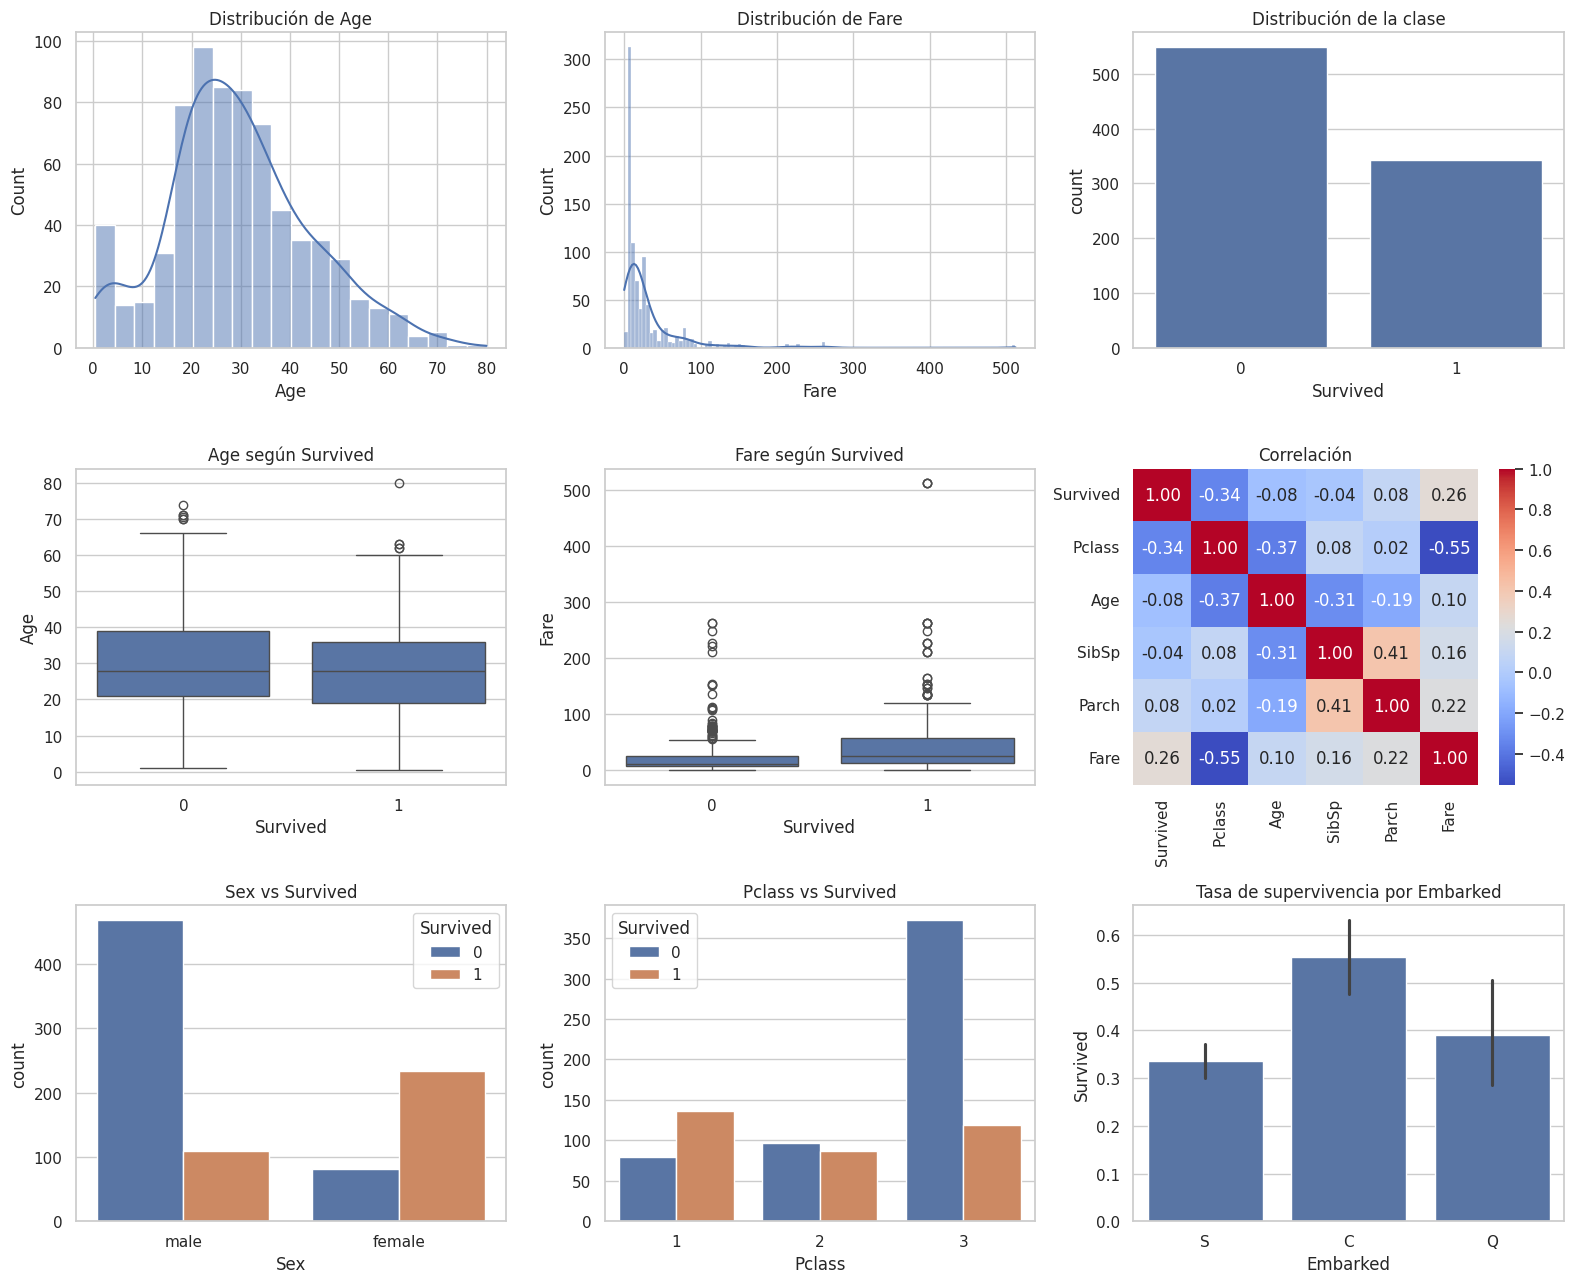

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(3, 3, figsize=(16, 13))

sns.histplot(titanic["Age"].dropna(), kde=True, ax=ax[0,0]); ax[0,0].set_title("Distribución de Age")
sns.histplot(titanic["Fare"], kde=True, ax=ax[0,1]); ax[0,1].set_title("Distribución de Fare")
sns.countplot(x="Survived", data=titanic, ax=ax[0,2]); ax[0,2].set_title("Distribución de la clase")

sns.boxplot(x="Survived", y="Age", data=titanic, ax=ax[1,0]); ax[1,0].set_title("Age según Survived")
sns.boxplot(x="Survived", y="Fare", data=titanic, ax=ax[1,1]); ax[1,1].set_title("Fare según Survived")
sns.heatmap(titanic[["Survived","Pclass","Age","SibSp","Parch","Fare"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1,2]); ax[1,2].set_title("Correlación")

sns.countplot(x="Sex", hue="Survived", data=titanic, ax=ax[2,0]); ax[2,0].set_title("Sex vs Survived")
sns.countplot(x="Pclass", hue="Survived", data=titanic, ax=ax[2,1]); ax[2,1].set_title("Pclass vs Survived")
sns.barplot(x="Embarked", y="Survived", data=titanic, ax=ax[2,2]); ax[2,2].set_title("Tasa de supervivencia por Embarked")

plt.tight_layout(); plt.show()

### EDA de Telco
- **Histogramas de `tenure` y `MonthlyCharges`:** ¿cómo se distribuyen la antigüedad y el cobro mensual?
- **Distribución de la clase:** ¿hay desbalance? (5,174 vs. 1,869)
- **Boxplots de `tenure` y `TotalCharges` por `Churn`:** ¿quién abandona?
- **Matriz de correlación:** `tenure` es la variable numérica más ligada al abandono.
- **`Contract` e `InternetService` vs. `Churn`:** ¿qué tipo de cliente se va más?

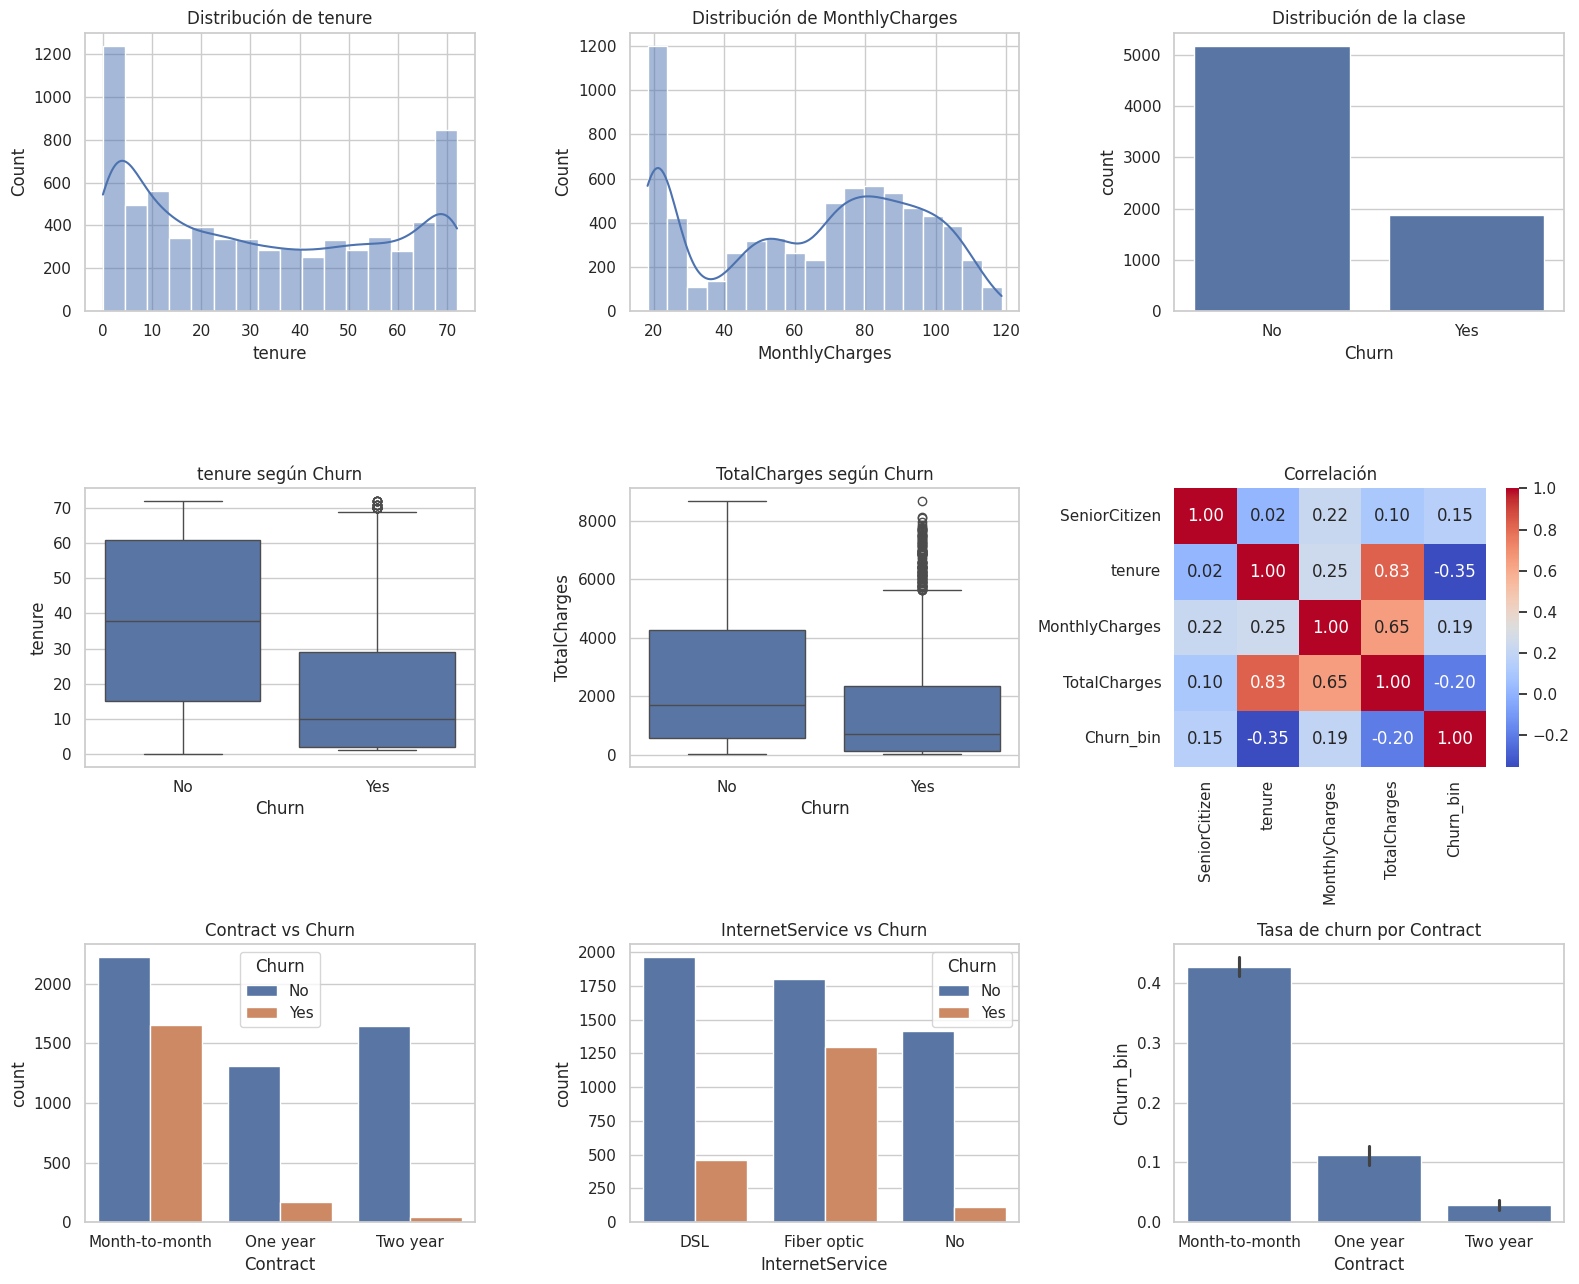

In [ ]:
telco["Churn_bin"] = (telco["Churn"] == "Yes").astype(int)

fig, ax = plt.subplots(3, 3, figsize=(16, 13))

sns.histplot(telco["tenure"], kde=True, ax=ax[0,0]); ax[0,0].set_title("Distribución de tenure")
sns.histplot(telco["MonthlyCharges"], kde=True, ax=ax[0,1]); ax[0,1].set_title("Distribución de MonthlyCharges")
sns.countplot(x="Churn", data=telco, ax=ax[0,2]); ax[0,2].set_title("Distribución de la clase")

sns.boxplot(x="Churn", y="tenure", data=telco, ax=ax[1,0]); ax[1,0].set_title("tenure según Churn")
sns.boxplot(x="Churn", y="TotalCharges", data=telco, ax=ax[1,1]); ax[1,1].set_title("TotalCharges según Churn")
sns.heatmap(telco[["SeniorCitizen","tenure","MonthlyCharges","TotalCharges","Churn_bin"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1,2]); ax[1,2].set_title("Correlación")

sns.countplot(x="Contract", hue="Churn", data=telco, ax=ax[2,0]); ax[2,0].set_title("Contract vs Churn")
sns.countplot(x="InternetService", hue="Churn", data=telco, ax=ax[2,1]); ax[2,1].set_title("InternetService vs Churn")
sns.barplot(x="Contract", y="Churn_bin", data=telco, ax=ax[2,2]); ax[2,2].set_title("Tasa de churn por Contract")

plt.tight_layout(); plt.show()

### Tasas exactas de abandono
Esta celda calcula las cifras que respaldan el hallazgo del EDA: tasa de abandono por tipo de contrato y de servicio de internet, y mediana de `tenure` según `Churn`.

In [ ]:
print((telco.groupby("Contract")["Churn_bin"].mean() * 100).round(1), "\n")
print((telco.groupby("InternetService")["Churn_bin"].mean() * 100).round(1), "\n")
print(telco.groupby("Churn")["tenure"].median())

## 4. Imputación de valores perdidos
Se separan los datos en entrenamiento (80 %) y prueba (20 %) con estratificación **antes** de imputar, y todos los valores de imputación se calculan solo con entrenamiento (dentro de pipelines) para evitar fuga de información.

Se comparan la estrategia A (media y moda) contra la B (mediana y "Desconocido"), más una variante con indicador de ausente.

In [ ]:
from sklearn.model_selection import train_test_split

X = titanic.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
X["Pclass"] = X["Pclass"].astype(str)   # es categórica
y = titanic["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print("Nulos en train:\n", X_train.isna().sum())

(712, 7) (179, 7)
Nulos en train:
 Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


### Efecto de la imputación en la distribución de `Age`
Se compara la distribución original (sin nulos) contra la imputada con media (A) y con mediana (B), revisando media, desviación estándar, asimetría y concentraciones artificiales.

,count,mean,std,min,25%,50%,75%,max,asimetria
original (sin nulos),575.0,29.81,14.49,0.42,21.0,28.50,39.0,80.0,0.35
A: media,712.0,29.81,13.02,0.42,22.0,29.81,36.0,80.0,0.39
B: mediana,712.0,29.56,13.03,0.42,22.0,28.50,36.0,80.0,0.45


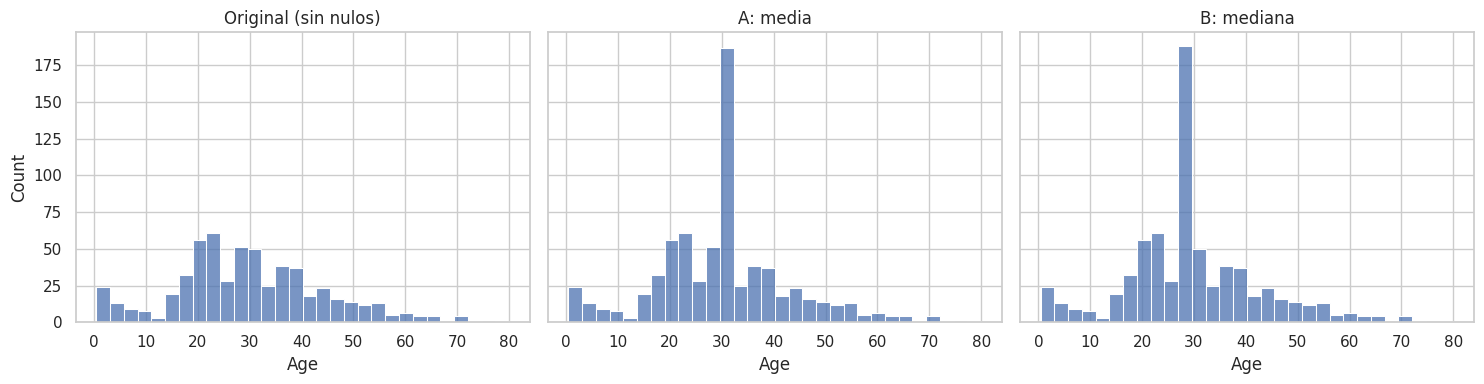

In [ ]:
age = X_train["Age"]
age_media = age.fillna(age.mean())
age_mediana = age.fillna(age.median())

comp = pd.DataFrame({
    "original (sin nulos)": age.dropna().describe(),
    "A: media": age_media.describe(),
    "B: mediana": age_mediana.describe(),
}).T
comp["asimetria"] = [age.dropna().skew(), age_media.skew(), age_mediana.skew()]
display(comp.round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
sns.histplot(age.dropna(), bins=30, ax=ax[0]); ax[0].set_title("Original (sin nulos)")
sns.histplot(age_media, bins=30, ax=ax[1]); ax[1].set_title("A: media")
sns.histplot(age_mediana, bins=30, ax=ax[2]); ax[2].set_title("B: mediana")
plt.tight_layout(); plt.show()

### Efecto de la imputación en el desempeño
Se evalúan tres estrategias dentro de un pipeline con validación cruzada (el imputador se ajusta solo con los folds de entrenamiento): A (media y moda), B (mediana y "Desconocido") y B con indicador binario de valor ausente.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked", "Pclass"]

def build(num_strategy, cat_strategy, indicator=False):
    num = Pipeline([("imp", SimpleImputer(strategy=num_strategy, add_indicator=indicator)),
                    ("sc", StandardScaler())])
    if cat_strategy == "moda":
        cat_imp = SimpleImputer(strategy="most_frequent")
    else:
        cat_imp = SimpleImputer(strategy="constant", fill_value="Desconocido")
    cat = Pipeline([("imp", cat_imp), ("oh", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

estrategias = {
    "A: media + moda": ("mean", "moda", False),
    "B: mediana + Desconocido": ("median", "desconocido", False),
    "B + indicador de ausente": ("median", "desconocido", True),
}

cv = StratifiedKFold(5, shuffle=True, random_state=42)
filas = []
for nombre, (ns, cs, ind) in estrategias.items():
    r = cross_validate(build(ns, cs, ind), X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "recall", "roc_auc"])
    filas.append({"estrategia": nombre,
                  **{m: round(r[f"test_{m}"].mean(), 3) for m in ["accuracy", "f1", "recall", "roc_auc"]}})
display(pd.DataFrame(filas))

,estrategia,accuracy,f1,recall,roc_auc
0,A: media + moda,0.801,0.729,0.700,0.853
1,B: mediana + Desconocido,0.802,0.730,0.700,0.853
2,B + indicador de ausente,0.796,0.723,0.692,0.853


### Conclusión de la imputación
Las estrategias A y B concentran los 137 valores imputados en un solo valor, lo que crea un pico artificial cerca de los 30 años (la barra más alta del histograma supera los 150 casos), y reducen la desviación estándar de `Age` de 14.49 a 13.0. El desempeño es equivalente (diferencias de 0.008 o menos en todas las métricas) y el indicador de ausente no mejoró el modelo.

**Decisión:** mediana y "Desconocido", por ser más robustas ante la asimetría y no inventar información. `Cabin` (77 % de nulos) no se imputa.

## 5. Winsorización de outliers (Fare)
Se comparan dos criterios, ambos con límites calculados solo con entrenamiento: rango intercuartílico (1.5 x IQR) y percentiles 1 y 99.

iqr: límites = [-26.76, 65.66] | recortados = 91 (12.8%)
pct: límites = [0.00, 227.53] | recortados = 7 (1.0%)


,mean,50%,std,min,max,asimetria
ninguno,31.82,14.45,48.06,0.0,512.33,4.65
iqr,23.96,14.45,20.51,0.0,65.66,1.08
pct,30.82,14.45,41.00,0.0,227.52,2.93


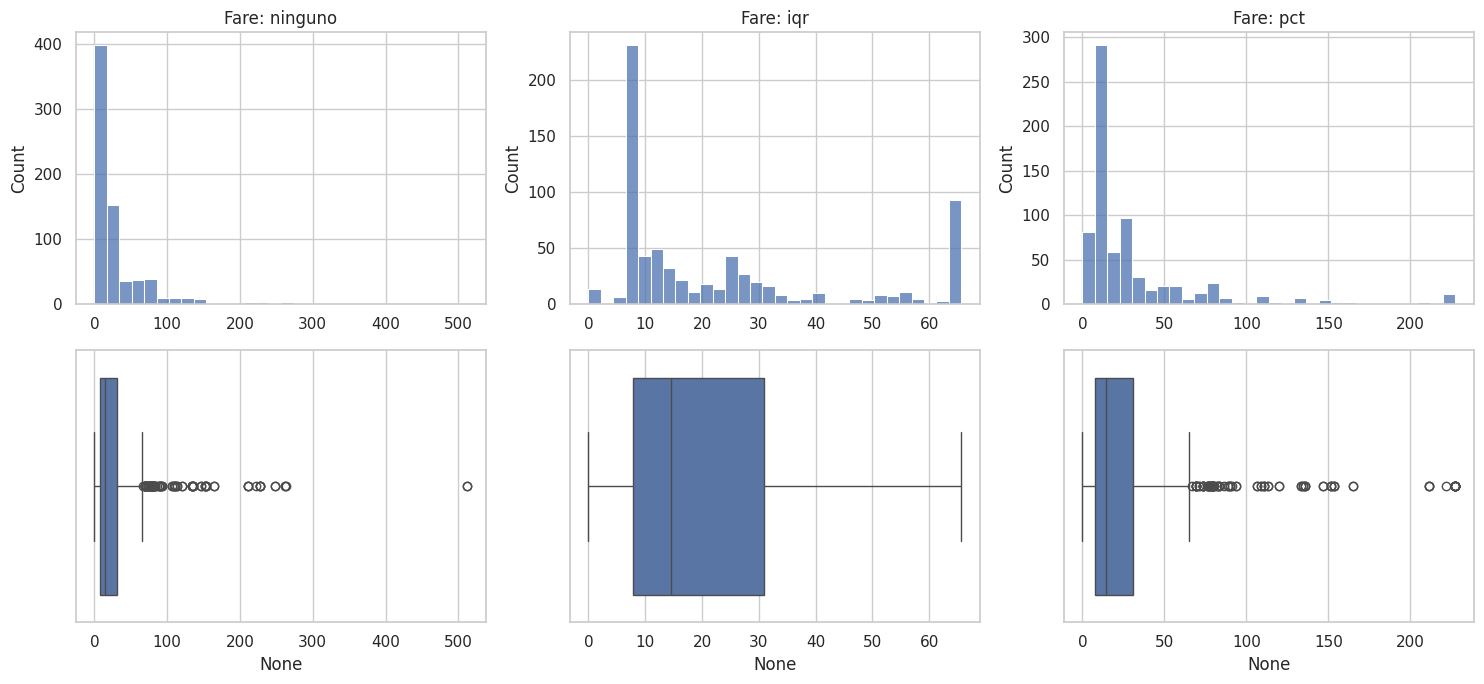

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, metodo="ninguno", k=1.5, p=(0.01, 0.99)):
        self.metodo, self.k, self.p = metodo, k, p
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        if self.metodo == "iqr":
            q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
            self.lo_, self.hi_ = q1 - self.k*(q3-q1), q3 + self.k*(q3-q1)
        elif self.metodo == "pct":
            self.lo_, self.hi_ = np.nanpercentile(X, [self.p[0]*100, self.p[1]*100], axis=0)
        else:
            self.lo_, self.hi_ = np.full(X.shape[1], -np.inf), np.full(X.shape[1], np.inf)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

fare = X_train[["Fare"]]
versiones = {}
for m in ["ninguno", "iqr", "pct"]:
    w = Winsorizer(m).fit(fare)
    versiones[m] = pd.Series(w.transform(fare).ravel())
    if m != "ninguno":
        n_rec = ((fare["Fare"] < w.lo_[0]) | (fare["Fare"] > w.hi_[0])).sum()
        print(f"{m}: límites = [{w.lo_[0]:.2f}, {w.hi_[0]:.2f}] | recortados = {n_rec} ({n_rec/len(fare)*100:.1f}%)")

tabla = pd.DataFrame({k: v.describe()[["mean","50%","std","min","max"]] for k, v in versiones.items()}).T
tabla["asimetria"] = [v.skew() for v in versiones.values()]
display(tabla.round(2))

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, (m, v) in enumerate(versiones.items()):
    sns.histplot(v, bins=30, ax=ax[0, i]); ax[0, i].set_title(f"Fare: {m}")
    sns.boxplot(x=v, ax=ax[1, i])
plt.tight_layout(); plt.show()

### Efecto de la winsorización en el desempeño
Se entrena el mismo modelo con `Fare` sin winsorizar, winsorizada por IQR y winsorizada por percentiles 1 y 99. El winsorizador está dentro del pipeline, así que sus límites se calculan solo con los folds de entrenamiento.

In [ ]:
def build_w(metodo):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    fare_p = Pipeline([("w", Winsorizer(metodo)), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Desconocido")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", num, ["Age", "SibSp", "Parch"]),
                             ("fare", fare_p, ["Fare"]),
                             ("cat", cat, ["Sex", "Embarked", "Pclass"])])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

filas = []
for m in ["ninguno", "iqr", "pct"]:
    r = cross_validate(build_w(m), X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "recall", "roc_auc"])
    filas.append({"winsor": m, **{k: round(r[f"test_{k}"].mean(), 3) for k in ["accuracy", "f1", "recall", "roc_auc"]}})
display(pd.DataFrame(filas))

,winsor,accuracy,f1,recall,roc_auc
0,ninguno,0.802,0.730,0.700,0.853
1,iqr,0.788,0.713,0.689,0.856
2,pct,0.802,0.730,0.700,0.852


### Conclusión de la winsorización
- IQR: recorta 91 filas (12.8 %), baja el máximo a 65.66 y reduce ligeramente el desempeño (accuracy 0.788).
- Percentiles 1 y 99: recorta solo 7 filas (1.0 %), baja el máximo a 227.53 y mantiene el desempeño (accuracy 0.802).

**Decisión:** percentiles 1 y 99. El IQR descarta tarifas altas legítimas de 1.ª clase, que no son errores de captura.

## 6. Tratamiento del desbalance (Telco)
Se calcula la razón de desbalance IR = clase mayoritaria / clase minoritaria. Con IR = 2.77 (5,174 vs. 1,869) el dataset está desbalanceado, porque supera el umbral de 1.5.

Se comparan cinco estrategias: sin balanceo, ponderación de clases, sobremuestreo aleatorio, submuestreo aleatorio y SMOTE. El balanceo se aplica **dentro** de la validación cruzada y solo sobre los folds de entrenamiento.

In [ ]:
conteo = telco["Churn"].value_counts()
print(pd.DataFrame({"n": conteo, "%": (conteo / len(telco) * 100).round(1)}))
IR = conteo.max() / conteo.min()
print(f"IR = {IR:.2f} ->", "desbalanceado" if IR > 1.5 else "balanceado")

          n     %
Churn            
No     5174  73.5
Yes    1869  26.5
IR = 2.77 -> desbalanceado


### Preparación de Telco para el modelado
- Se elimina `customerID` (identificador).
- Se unifican "No internet service" y "No phone service" con "No".
- `SeniorCitizen` se trata como categórica.
- Se separa 80 % entrenamiento y 20 % prueba con estratificación, y se arma el preprocesador (mediana y escalado para numéricas, one-hot para categóricas).

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

T = telco.drop(columns=["customerID", "Churn", "Churn_bin"]).copy()
T = T.replace({"No internet service": "No", "No phone service": "No"})
T["SeniorCitizen"] = T["SeniorCitizen"].astype(str)
t = telco["Churn_bin"]

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    T, t, test_size=0.2, stratify=t, random_state=42)

num_t = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_t = [c for c in T.columns if c not in num_t]

pre_t = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_t),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_t)])

### Comparación de las cinco estrategias
Para cada estrategia se calculan accuracy, precision, recall, F1 y ROC-AUC con validación cruzada de 5 folds. El sobremuestreo, el submuestreo y SMOTE están dentro del pipeline de `imblearn`, por lo que solo actúan sobre los folds de entrenamiento.

In [ ]:
def build_bal(nombre):
    clf = LogisticRegression(max_iter=1000,
          class_weight="balanced" if nombre == "Ponderación de clases" else None)
    sampler = {"Sobremuestreo aleatorio": RandomOverSampler(random_state=42),
               "Submuestreo aleatorio": RandomUnderSampler(random_state=42),
               "SMOTE": SMOTE(random_state=42)}.get(nombre)
    pasos = [("pre", pre_t)] + ([("samp", sampler)] if sampler else []) + [("clf", clf)]
    return ImbPipeline(pasos)

nombres = ["Sin balanceo", "Ponderación de clases", "Sobremuestreo aleatorio",
           "Submuestreo aleatorio", "SMOTE"]
filas = []
for n in nombres:
    r = cross_validate(build_bal(n), Xt_train, yt_train, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    filas.append({"estrategia": n, **{m: round(r[f"test_{m}"].mean(), 3)
                  for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
display(pd.DataFrame(filas))

,estrategia,accuracy,precision,recall,f1,roc_auc
0,Sin balanceo,0.802,0.653,0.542,0.592,0.846
1,Ponderación de clases,0.749,0.518,0.803,0.629,0.846
2,Sobremuestreo aleatorio,0.748,0.516,0.802,0.628,0.846
3,Submuestreo aleatorio,0.746,0.514,0.800,0.626,0.846
4,SMOTE,0.756,0.527,0.791,0.632,0.845


### Conclusión del balanceo
Un modelo que siempre responde "No abandona" ya tiene 73.5 % de accuracy, por lo que esa métrica por sí sola es engañosa. Todas las estrategias de balanceo suben el recall de 0.54 a cerca de 0.80 a costa de precisión, y el ROC-AUC no cambia (0.846): el balanceo mueve el punto de corte, no mejora la capacidad de ordenar clientes por riesgo. Las cuatro técnicas rinden casi igual (F1 entre 0.626 y 0.632).

**Decisión:** ponderación de clases, por ser la más simple y no duplicar, inventar ni descartar datos.

## 7. Evaluación final
Se entrenan el modelo sin balanceo y el de ponderación de clases sobre todo el entrenamiento y se evalúan en el conjunto de prueba (datos nunca vistos), con reporte de clasificación y matriz de confusión. Como referencia, predecir siempre "No" daría 73.5 % de accuracy.

Accuracy de predecir siempre 'No': 0.735

 Sin balanceo
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409


 Ponderación de clases
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



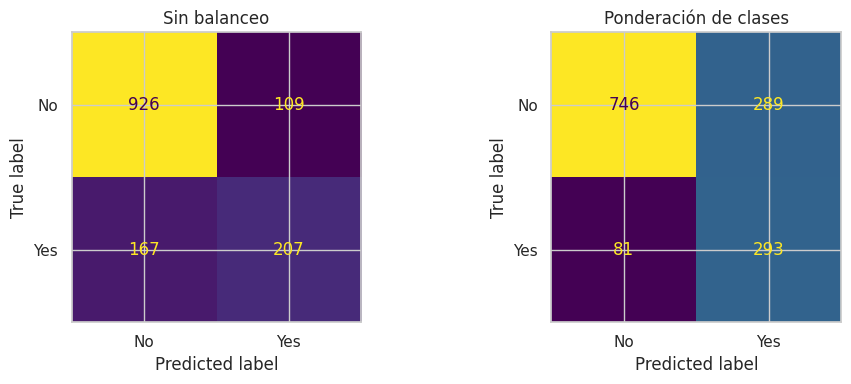

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print("Accuracy de predecir siempre 'No':", round(1 - yt_test.mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, n in zip(ax, ["Sin balanceo", "Ponderación de clases"]):
    modelo = build_bal(n).fit(Xt_train, yt_train)
    pred = modelo.predict(Xt_test)
    print("\n", n)
    print(classification_report(yt_test, pred, target_names=["No", "Yes"]))
    ConfusionMatrixDisplay.from_predictions(yt_test, pred, display_labels=["No", "Yes"],
                                            ax=a, colorbar=False)
    a.set_title(n)
plt.tight_layout(); plt.show()

### Conclusiones
En el conjunto de prueba, conformado por 1,409 clientes de los cuales 374 corresponden a un abandono real, la implementación de la ponderación de clases permitió identificar 293 casos de deserción (alcanzando un recall de 0.78), en contraste con los 207 detectados por el modelo sin balanceo (recall de 0.55). Sin embargo , este incremento en la sensibilidad conlleva un aumento en los falsos positivos, registrando 289 alarmas erróneas frente a las 109 del modelo base.

